# 03 · Validity: the source shortcut and the image effect

On MMFakeBench each row names a text source and an image source. This notebook asks how much of the label those names give away, and whether showing the image changes the model's answers.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

ROOT = Path.cwd().resolve().parents[1]
FIG = ROOT / "MIDTERM_PRETRAINED_BASELINE" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = ROOT / "dashboard" / "results.json"
PAIR_PATH = ROOT / "data" / "reports" / "baseline_study" / "mmfakebench_source_pair_effect_2026-10-25.json"

with RESULTS_PATH.open() as fh:
    results = json.load(fh)
with PAIR_PATH.open() as fh:
    pair_effect = json.load(fh)

validity = results["validity"]
runs = {run["key"]: run for run in results["runs"]}
mm_full = results["differences"]["mm_full"]
pooled = pair_effect["pooled"]
pairs = pair_effect["pairs"]
across = pair_effect["across_pairs"]
LABELS = validity["source_rule"]["labels"]
assert LABELS == ["original", "textual_veracity_distortion", "visual_veracity_distortion", "mismatch"]

print("results.json keys:", list(results))
print("pair-effect keys:", list(pair_effect))


def pct(x):
    return f"{100 * x:.1f}"


def signed_pp(x):
    return f"{100 * x:+.2f}"


def pp_range(lo, hi):
    return f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"


def count(n):
    return f"{n:,}"


def src(name):
    return name if name else "(empty)"


results.json keys: ['meta', 'runs', 'differences', 'validity', 'timeline']
pair-effect keys: ['across_pairs', 'date', 'inputs', 'method', 'new_inference', 'pairs', 'pooled']


## Part 1 · The source-name rule

,Accuracy (%),Macro-F1 (%),n
Row,,,
"Source-name rule (fit on validation, scored on test)",91.5,85.1,"9,999"
"In-sample ceiling (majority label per pair, same rows)",95.0,n/a,"9,999"
Constant majority (original),30.0,11.5,"9,999"
"Model, text only",27.9,21.8,"10,000"
"Model, image + text",26.4,20.4,"9,999"


The text-only run has 10,000 usable rows and the paired run has 9,999. The Part 2 comparison uses the 9,999 shared rows.


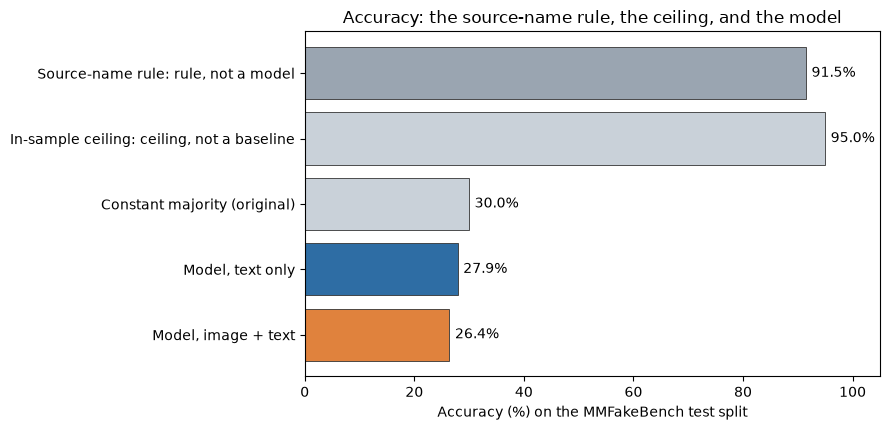

In [2]:
src_rule = validity["source_rule"]
ceiling = validity["ceiling"]
majority = validity["majority"]
text_run = runs["mm_text"]
paired_run = runs["mm_paired"]

# (row name, accuracy, macro-F1 or None, n, chart label)
rows = [
    ("Source-name rule (fit on validation, scored on test)", src_rule["accuracy"], src_rule["macro_f1"],
     src_rule["n"], "Source-name rule: rule, not a model"),
    ("In-sample ceiling (majority label per pair, same rows)", ceiling["accuracy"], None,
     ceiling["n"], "In-sample ceiling: ceiling, not a baseline"),
    (f"Constant majority ({majority['label']})", majority["accuracy"], majority["macro_f1"],
     majority["n"], f"Constant majority ({majority['label']})"),
    ("Model, text only", text_run["accuracy"], text_run["macro_f1"],
     text_run["counts"]["usable"], "Model, text only"),
    ("Model, image + text", paired_run["accuracy"], paired_run["macro_f1"],
     paired_run["counts"]["usable"], "Model, image + text"),
]

table = pd.DataFrame(
    [
        {
            "Row": r[0],
            "Accuracy (%)": pct(r[1]),
            "Macro-F1 (%)": "n/a" if r[2] is None else pct(r[2]),
            "n": count(r[3]),
        }
        for r in rows
    ]
).set_index("Row")
display(table)
print(f"The text-only run has {count(text_run['counts']['usable'])} usable rows and the paired run has "
      f"{count(paired_run['counts']['usable'])}. The Part 2 comparison uses the "
      f"{count(mm_full['shared_rows'])} shared rows.")

fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(rows))
values = [100 * r[1] for r in rows]
colors = ["#9aa5b1", "#c9d1d9", "#c9d1d9", "#2e6da4", "#e0823d"]
bars = ax.barh(y, values, color=colors, edgecolor="#333333", linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels([r[4] for r in rows])
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xlabel("Accuracy (%) on the MMFakeBench test split")
ax.set_title("Accuracy: the source-name rule, the ceiling, and the model")
for bar, v in zip(bars, values):
    ax.text(v + 1, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center")
fig.tight_layout()
fig.savefig(FIG / "03_source_rule_vs_model.png", dpi=150, bbox_inches="tight")
plt.show()


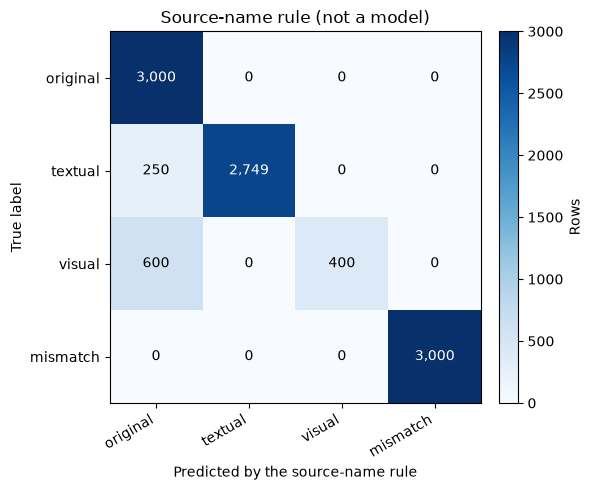

In [3]:
cm = np.array(src_rule["confusion"])
assert cm.sum(axis=1).tolist() == [src_rule["per_class"][l]["support"] for l in LABELS]
assert abs(np.trace(cm) / cm.sum() - src_rule["accuracy"]) < 1e-12

short = ["original", "textual", "visual", "mismatch"]
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4))
ax.set_xticklabels(short, rotation=30, ha="right")
ax.set_yticks(range(4))
ax.set_yticklabels(short)
ax.set_xlabel("Predicted by the source-name rule")
ax.set_ylabel("True label")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Source-name rule (not a model)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Rows")
fig.tight_layout()
fig.savefig(FIG / "03_source_rule_confusion.png", dpi=150, bbox_inches="tight")
plt.show()


Thirteen of the 14 source pairs carry a single label, so the rule reaches its accuracy without seeing any image or text. Aggregate MMFakeBench scores must be read against this rule.

## Part 2 · Does the image change the answer? (by source pair)

In [4]:
pooled_diff = pooled["difference"]
pooled_lo, pooled_hi = pooled["difference_95"]
assert abs(pooled_diff - (mm_full["accuracy_a"] - mm_full["accuracy_b"])) < 1e-12, \
    "pooled difference does not match the saved ablation"
assert pooled["n"] == mm_full["shared_rows"], "pooled n does not match the saved ablation"

print(f"Pooled difference (paired minus text-only): {signed_pp(pooled_diff)} pp")
print(f"95% range: {pp_range(pooled_lo, pooled_hi)} pp")
print(f"n = {count(pooled['n'])} shared rows, {count(pooled['clusters'])} image clusters")
print("pooled value matches the saved ablation")


Pooled difference (paired minus text-only): -1.51 pp
95% range: [-2.44, -0.54] pp
n = 9,999 shared rows, 9,716 image clusters
pooled value matches the saved ablation


In [5]:
def gold_text(gold):
    if len(gold) == 1:
        return next(iter(gold))
    return " / ".join(f"{k} {count(v)}" for k, v in gold.items())


records = []
for q in sorted(pairs, key=lambda q: q["difference"]):
    lo, hi = q["difference_95"]
    records.append({
        "text_source": src(q["text_source"]),
        "image_source": src(q["image_source"]),
        "n": count(q["n"]),
        "gold label": gold_text(q["gold"]),
        "paired acc (%)": pct(q["accuracy_paired"]),
        "text-only acc (%)": pct(q["accuracy_text"]),
        "difference (pp)": signed_pp(q["difference"]),
        "95% range (pp)": pp_range(lo, hi),
        "image fixed": q["image_fixed"],
        "image broke": q["image_broke"],
    })
pair_table = pd.DataFrame(records)
display(pair_table)

# Image fixed: paired correct, text-only wrong. Image broke: the reverse.
for q in pairs:
    assert abs((q["image_fixed"] - q["image_broke"]) - q["difference"] * q["n"]) < 1e-6
print("On every pair, image fixed minus image broke equals the accuracy difference multiplied by n.")


,text_source,image_source,n,gold label,paired acc (%),text-only acc (%),difference (pp),95% range (pp),image fixed,image broke
0,Gossipcop,AI-generated Image,250,textual_veracity_distortion,72.4,90.4,-18.00,"[-23.60, -12.00]",9,54
1,VisualNews,AI-generated Image,50,visual_veracity_distortion,2.0,20.0,-18.00,"[-30.00, -6.00]",1,10
2,GPT-generated Rumor,AI-generated Image,500,textual_veracity_distortion,33.4,51.2,-17.80,"[-23.00, -12.80]",51,140
3,Newsclipings,Newsclipings,"1,500",mismatch,12.5,18.3,-5.80,"[-8.12, -3.52]",128,215
4,VisualNews,VisualNews,"2,000",original,13.5,18.6,-5.10,"[-7.10, -3.15]",156,258
5,(empty),(empty),100,visual_veracity_distortion,0.0,5.0,-5.00,"[-10.00, -1.00]",0,5
6,Fakeddit,Fakeddit,"1,000",original 500 / visual_veracity_distortion 500,7.6,10.4,-2.80,"[-5.01, -0.50]",49,77
7,Fakenewsnet,Repurposed Image,750,textual_veracity_distortion,81.3,83.3,-2.00,"[-5.53, +1.32]",73,88
8,Fever,AI-generated Image,999,textual_veracity_distortion,24.3,23.9,+0.40,"[-3.10, +3.70]",154,150
9,GPT-generated Rumor,Repurposed Image,500,textual_veracity_distortion,74.0,72.0,+2.00,"[-3.09, +6.95]",85,75


On every pair, image fixed minus image broke equals the accuracy difference multiplied by n.


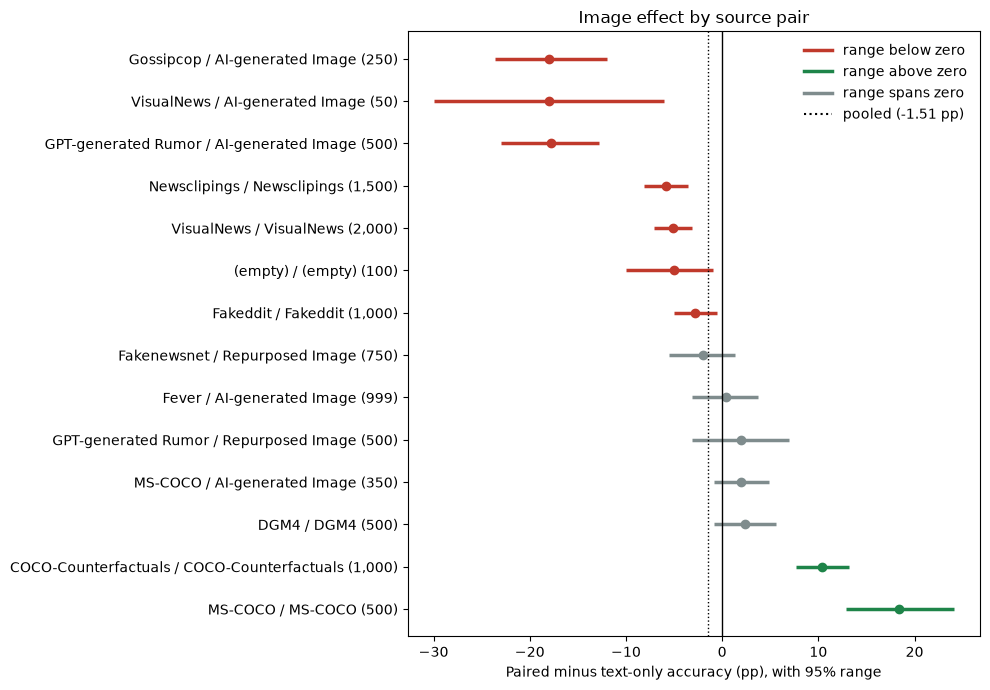

In [6]:
ordered = sorted(pairs, key=lambda q: q["difference"])
ys = np.arange(len(ordered))[::-1]
RED, GREEN, GREY = "#c0392b", "#1e8449", "#7f8c8d"

fig, ax = plt.subplots(figsize=(10, 7))
for y, q in zip(ys, ordered):
    lo = 100 * q["difference_95"][0]
    hi = 100 * q["difference_95"][1]
    d = 100 * q["difference"]
    color = RED if hi < 0 else GREEN if lo > 0 else GREY
    ax.hlines(y, lo, hi, color=color, linewidth=2.5)
    ax.plot(d, y, "o", color=color, markersize=6)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(100 * pooled_diff, color="black", linestyle=":", linewidth=1)
ax.set_yticks(ys)
ax.set_yticklabels([f"{src(q['text_source'])} / {src(q['image_source'])} ({count(q['n'])})" for q in ordered])
ax.set_xlabel("Paired minus text-only accuracy (pp), with 95% range")
ax.set_title("Image effect by source pair")
handles = [
    Line2D([0], [0], color=RED, lw=2.5, label="range below zero"),
    Line2D([0], [0], color=GREEN, lw=2.5, label="range above zero"),
    Line2D([0], [0], color=GREY, lw=2.5, label="range spans zero"),
    Line2D([0], [0], color="black", linestyle=":", label=f"pooled ({signed_pp(pooled_diff)} pp)"),
]
ax.legend(handles=handles, loc="upper right", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "03_image_effect_by_pair.png", dpi=150, bbox_inches="tight")
plt.show()


In [7]:
below = sum(q["difference_95"][1] < 0 for q in pairs)
above = sum(q["difference_95"][0] > 0 for q in pairs)
spanning = len(pairs) - below - above
assert (below, above, spanning) == (across["pairs_range_below_zero"], across["pairs_range_above_zero"],
                                    across["pairs_range_spans_zero"])

n_total = sum(q["n"] for q in pairs)
assert n_total == pooled["n"]
n_weighted = sum(q["n"] * q["difference"] for q in pairs) / n_total
assert abs(n_weighted - pooled["difference"]) < 1e-12

equal_weight = sum(q["difference"] for q in pairs) / len(pairs)
assert abs(equal_weight - across["equal_weight_difference"]) < 1e-12

diffs = [q["difference"] for q in pairs]
print(f"Pairs with range below zero: {below}; above zero: {above}; spanning zero: {spanning} (of {len(pairs)})")
print(f"n-weighted mean difference: {signed_pp(n_weighted)} pp (equals the pooled value)")
print(f"Equal-weight mean difference: {signed_pp(equal_weight)} pp, "
      f"95% range {pp_range(*across['equal_weight_difference_95'])} pp")
print(f"Pair differences run from {signed_pp(min(diffs))} to {signed_pp(max(diffs))} pp")
print(f"Image clusters spanning more than one pair: {across['clusters_spanning_pairs']}")


Pairs with range below zero: 7; above zero: 2; spanning zero: 5 (of 14)
n-weighted mean difference: -1.51 pp (equals the pooled value)
Equal-weight mean difference: -2.78 pp, 95% range [-4.20, -1.47] pp
Pair differences run from -18.00 to +18.40 pp
Image clusters spanning more than one pair: 36


In [8]:
def mix_table(paired, text):
    return pd.DataFrame(
        {
            "paired (%)": [pct(paired.get(l, 0.0)) for l in LABELS],
            "text-only (%)": [pct(text.get(l, 0.0)) for l in LABELS],
            "change (pp)": [signed_pp(paired.get(l, 0.0) - text.get(l, 0.0)) for l in LABELS],
        },
        index=LABELS,
    )


def find_pair(text_name, image_name):
    matches = [q for q in pairs if q["text_source"] == text_name and q["image_source"] == image_name]
    assert len(matches) == 1
    return matches[0]


print(f"Predicted-label mix, all {count(pooled['n'])} rows")
display(mix_table(pooled["predicted_share_paired"], pooled["predicted_share_text"]))

for text_name, image_name in [("MS-COCO", "MS-COCO"), ("Gossipcop", "AI-generated Image")]:
    q = find_pair(text_name, image_name)
    print(f"Pair ({text_name}, {image_name}), n = {count(q['n'])}")
    display(mix_table(q["predicted_share_paired"], q["predicted_share_text"]))

pure = [q for q in pairs if q["label_pure"]]
assert len(pure) == ceiling["pure_pairs"]
for q in pure:
    label = next(iter(q["gold"]))
    assert abs(q["accuracy_paired"] - q["predicted_share_paired"].get(label, 0.0)) < 1e-12
    assert abs(q["accuracy_text"] - q["predicted_share_text"].get(label, 0.0)) < 1e-12
print(f"In all {len(pure)} label-pure pairs, accuracy equals the share of rows predicted as that pair's label, "
      "in both arms.")


Predicted-label mix, all 9,999 rows


,paired (%),text-only (%),change (pp)
original,24.6,25.1,-0.49
textual_veracity_distortion,55.5,57.6,-2.15
visual_veracity_distortion,1.0,3.9,-2.93
mismatch,19.0,13.4,+5.57


Pair (MS-COCO, MS-COCO), n = 500


,paired (%),text-only (%),change (pp)
original,60.4,42.0,+18.40
textual_veracity_distortion,12.8,49.4,-36.60
visual_veracity_distortion,4.8,0.8,+4.00
mismatch,22.0,7.8,+14.20


Pair (Gossipcop, AI-generated Image), n = 250


,paired (%),text-only (%),change (pp)
original,2.4,3.6,-1.20
textual_veracity_distortion,72.4,90.4,-18.00
visual_veracity_distortion,0.0,2.8,-2.80
mismatch,25.2,3.2,+22.00


In all 13 label-pure pairs, accuracy equals the share of rows predicted as that pair's label, in both arms.


In [9]:
mixed = [q for q in pairs if not q["label_pure"]]
assert len(mixed) == 1
m = mixed[0]
print(f"Mixed pair: text_source = {src(m['text_source'])}, image_source = {src(m['image_source'])}, "
      f"n = {count(m['n'])}")
print("Gold counts: " + ", ".join(f"{k} {count(v)}" for k, v in m["gold"].items()))
print(f"Within-pair macro-F1 over the two labels: paired {pct(m['macro_f1_paired_within_pair'])}%, "
      f"text-only {pct(m['macro_f1_text_within_pair'])}%")


Mixed pair: text_source = Fakeddit, image_source = Fakeddit, n = 1,000
Gold counts: original 500, visual_veracity_distortion 500
Within-pair macro-F1 over the two labels: paired 11.2%, text-only 14.2%


## Takeaways

- The source-name rule reaches 91.5% accuracy (macro-F1 85.1%). The model scores 26.4% with the image and 27.9% text-only, and a constant guess of "original" scores 30.0%. The rule uses only source names, so the model sits well below what the names alone supply.
- Pooled over the 9,999 shared rows, showing the image changes accuracy by -1.51 pp (95% range -2.44 to -0.54). Pair ranges run from -18.0 to +18.4 pp, with 7 pairs below zero, 2 above and 5 spanning zero. The equal-weight mean is -2.78 pp. The pooled figure averages large opposite effects, so it does not describe a typical image effect.
- In the 13 label-pure pairs, accuracy equals the share of rows the model assigns to that pair's label, in both arms. The image therefore mostly shifts which label the model picks. In the MS-COCO pair, the share predicted as "original" rises from 42.0% to 60.4%, which accounts for the whole +18.4 pp.
- The one mixed pair, Fakeddit with Fakeddit (500 original, 500 visual distortion), has within-pair macro-F1 of 11.2% with the image and 14.2% text-only. On that pair the image lowers macro-F1.